In [1]:
!pip install -q requests pandas tqdm

In [11]:
import json
import time
from pathlib import Path

import pandas as pd
import requests
from tqdm.auto import tqdm

APP_ID = 413150
API_URL = (
    "https://api.steampowered.com/"
    "IUserReviewsService/GetAppReviews/v1/"
)

TARGET_REVIEWS = 50_000
OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_PATH = OUTPUT_DIR / "dataset_raw.csv"

print("App ID:", APP_ID)
print("Target ulasan:", f"{TARGET_REVIEWS:,}")
print("Output:", RAW_PATH)

App ID: 413150
Target ulasan: 50,000
Output: data/dataset_raw.csv


In [12]:
def fetch_reviews(target_count=50_000, pause=1.0):
    session = requests.Session()

    cursor = "*"
    seen_ids = set()
    seen_cursors = set()
    rows = []

    progress = tqdm(total=target_count, desc="Scraping Steam")

    while len(rows) < target_count:
        remaining = target_count - len(rows)

        payload = {
            "appid": APP_ID,
            "filter": 1,
            "language": "english",
            "review_type": 0,
            "purchase_type": 0,
            "num_per_page": min(100, remaining),
            "cursor": cursor,
        }

        try:
            response = session.get(
                API_URL,
                params={
                    "input_json": json.dumps(payload)
                },
                timeout=30,
            )

            if response.status_code == 429:
                retry_after = response.headers.get("Retry-After")
                wait_seconds = (
                    int(retry_after)
                    if retry_after and retry_after.isdigit()
                    else 15
                )
                print(
                    f"\nRate limit Steam. "
                    f"Menunggu {wait_seconds} detik."
                )
                time.sleep(wait_seconds)
                continue

            response.raise_for_status()
            result = response.json()

        except (requests.RequestException, ValueError) as exc:
            print(f"\nPengambilan data gagal: {exc}")
            break

        data = result.get("response", result)
        reviews = data.get("reviews", [])

        if not reviews:
            print("\nSteam tidak mengembalikan ulasan lagi.")
            break

        added = 0

        for item in reviews:
            review_id = str(
                item.get("recommendationid", "")
            ).strip()

            text = (item.get("review") or "").strip()

            if not review_id or not text:
                continue

            if review_id in seen_ids:
                continue

            if item.get("language") != "english":
                continue

            author = item.get("author") or {}

            rows.append({
                "review_id": review_id,
                "review_text": text,
                "language": item.get("language"),
                "voted_up": item.get("voted_up"),
                "timestamp_created": item.get(
                    "timestamp_created"
                ),
                "timestamp_updated": item.get(
                    "timestamp_updated"
                ),
                "votes_up": item.get("votes_up"),
                "votes_funny": item.get("votes_funny"),
                "playtime_at_review": author.get(
                    "playtime_at_review"
                ),
                "playtime_forever": author.get(
                    "playtime_forever"
                ),
                "steam_purchase": item.get("steam_purchase"),
                "received_for_free": item.get(
                    "received_for_free"
                ),
            })

            seen_ids.add(review_id)
            added += 1
            progress.update(1)

            if len(rows) >= target_count:
                break

        next_cursor = data.get("cursor")

        if not next_cursor:
            print("\nCursor tidak tersedia.")
            break

        if next_cursor == cursor or next_cursor in seen_cursors:
            print("\nCursor tidak bergerak; scraping dihentikan.")
            break

        if added == 0:
            print("\nTidak ada ulasan baru pada halaman ini.")
            break

        seen_cursors.add(cursor)
        cursor = next_cursor

        time.sleep(pause)

    progress.close()
    session.close()

    return pd.DataFrame(rows)

In [13]:
df_raw = fetch_reviews(
    target_count=TARGET_REVIEWS,
    pause=1.0,
)

if df_raw.empty:
    raise RuntimeError(
        "Tidak ada ulasan yang terkumpul. "
        "Periksa koneksi, respons Steam API, dan parameter request."
    )

df_raw = (
    df_raw
    .drop_duplicates(subset="review_id")
    .reset_index(drop=True)
)

df_raw.to_csv(
    RAW_PATH,
    index=False,
    encoding="utf-8",
)

print("Scraping selesai.")
print("Jumlah data:", f"{len(df_raw):,}")
print("Jumlah ID unik:", df_raw["review_id"].nunique())
print("Lokasi file:", RAW_PATH.resolve())

Scraping Steam:   0%|          | 0/50000 [00:00<?, ?it/s]

Scraping selesai.
Jumlah data: 50,000
Jumlah ID unik: 50000
Lokasi file: /content/data/dataset_raw.csv


In [14]:
print("Dimensi dataset:", df_raw.shape)
print("\nNama kolom:")
print(df_raw.columns.tolist())

print("\nContoh lima ulasan:")
display(
    df_raw[
        [
            "review_id",
            "review_text",
            "voted_up",
            "language",
        ]
    ].head()
)

print("\nJumlah teks kosong:")
print(df_raw["review_text"].isna().sum())

print("\nDistribusi rekomendasi Steam:")
print(df_raw["voted_up"].value_counts(dropna=False))

Dimensi dataset: (50000, 12)

Nama kolom:
['review_id', 'review_text', 'language', 'voted_up', 'timestamp_created', 'timestamp_updated', 'votes_up', 'votes_funny', 'playtime_at_review', 'playtime_forever', 'steam_purchase', 'received_for_free']

Contoh lima ulasan:


,review_id,review_text,voted_up,language
0,238382718,"Stardew Valley is a great, relaxing game if yo...",True,english
1,238381711,banegr w chuj,True,english
2,238381581,Need More Joja Cola,True,english
3,238381441,FUN,True,english
4,238375566,(PS: Spoilers)\n\n\n\n\n\n\n\n\n\nFun and bit ...,True,english



Jumlah teks kosong:
0

Distribusi rekomendasi Steam:
voted_up
True     49148
False      852
Name: count, dtype: int64


In [15]:
df_raw["review_length"] = (
    df_raw["review_text"].astype(str).str.len()
)

print(
    df_raw["review_length"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95]
    )
)

print(
    "\nJumlah review dengan teks sangat pendek:",
    (df_raw["review_length"] < 5).sum()
)

print("\nBahasa data:")
print(df_raw["language"].value_counts(dropna=False))

count    50000.000000
mean       103.240320
std        261.651303
min          1.000000
25%         12.000000
50%         34.000000
75%         97.000000
95%        396.000000
max       8000.000000
Name: review_length, dtype: float64

Jumlah review dengan teks sangat pendek: 4841

Bahasa data:
language
english    50000
Name: count, dtype: int64


In [7]:
!pip install -q vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 4.0 MB/s eta 0:00:00


In [16]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def label_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score <= -0.05:
        return "negatif"
    elif score >= 0.05:
        return "positif"
    else:
        return "netral"


df_raw["sentiment_score"] = df_raw["review_text"].apply(
    lambda text: analyzer.polarity_scores(str(text))["compound"]
)

df_raw["sentiment"] = df_raw["sentiment_score"].apply(
    lambda score: (
        "negatif" if score <= -0.05
        else "positif" if score >= 0.05
        else "netral"
    )
)

display(
    df_raw[
        ["review_text", "sentiment_score", "sentiment"]
    ].head(10)
)

,review_text,sentiment_score,sentiment
0,"Stardew Valley is a great, relaxing game if yo...",0.9231,positif
1,banegr w chuj,0.0000,netral
2,Need More Joja Cola,0.0000,netral
3,FUN,0.5106,positif
4,(PS: Spoilers)\n\n\n\n\n\n\n\n\n\nFun and bit ...,0.9943,positif
5,baba,0.0000,netral
6,KJHGFDSA,0.0000,netral
7,meh,-0.0772,negatif
8,Chill,0.0000,netral
9,best game ever,0.6369,positif


,jumlah
sentiment,
positif,36137
netral,10997
negatif,2866


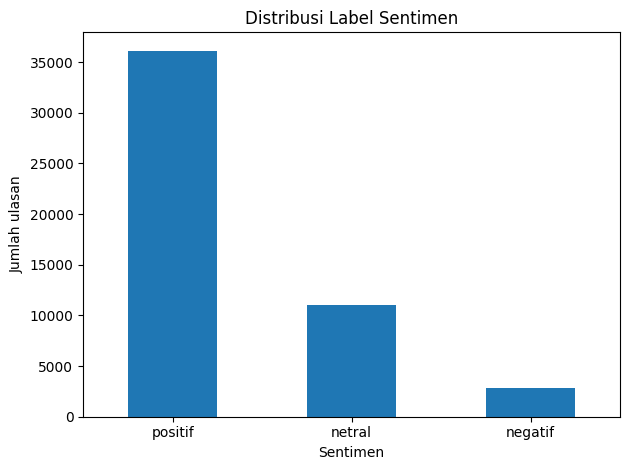

In [17]:
import matplotlib.pyplot as plt

class_counts = df_raw["sentiment"].value_counts()

display(class_counts.to_frame("jumlah"))

class_counts.plot(
    kind="bar",
    title="Distribusi Label Sentimen",
    xlabel="Sentimen",
    ylabel="Jumlah ulasan",
    rot=0,
)

plt.tight_layout()
plt.show()

In [26]:
df_labeled = df_raw.dropna(
    subset=["review_text", "sentiment"]
).copy()

df_labeled["review_text"] = (
    df_labeled["review_text"].astype(str).str.strip()
)

df_labeled = df_labeled[
    df_labeled["review_text"].ne("")
]

print("Distribusi sebelum sampling:")
print(df_labeled["sentiment"].value_counts())

target_counts = {
    "negatif": 2866,
    "netral": 4000,
    "positif": 8134,
}

available_counts = df_labeled["sentiment"].value_counts()

for label, target in target_counts.items():
    available = int(available_counts.get(label, 0))
    if available < target:
        raise ValueError(
            f"Data {label} hanya {available}, "
            f"sedangkan target {target}."
        )

sampled_frames = []

for label, target in target_counts.items():
    class_df = df_labeled[
        df_labeled["sentiment"] == label
    ]

    sampled_frames.append(
        class_df.sample(
            n=target,
            random_state=42,
            replace=False
        )
    )

df_balanced = (
    pd.concat(sampled_frames, ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("\nDistribusi setelah sampling:")
print(df_balanced["sentiment"].value_counts())

print("\nTotal sampel:", len(df_balanced))

Distribusi sebelum sampling:
sentiment
positif    36137
netral     10997
negatif     2866
Name: count, dtype: int64

Distribusi setelah sampling:
sentiment
positif    8134
netral     4000
negatif    2866
Name: count, dtype: int64

Total sampel: 15000


In [27]:
FINAL_PATH = "dataset.csv"

df_balanced.to_csv(
    FINAL_PATH,
    index=False,
    encoding="utf-8"
)

print("Dataset tersimpan:", FINAL_PATH)
print("Jumlah sampel:", len(df_balanced))
print("Distribusi kelas:")
print(df_balanced["sentiment"].value_counts())


Dataset tersimpan: dataset.csv
Jumlah sampel: 15000
Distribusi kelas:
sentiment
positif    8134
netral     4000
negatif    2866
Name: count, dtype: int64
